In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Sales_Revenue_train.csv")
print("dataset loaded successfully !")

dataset loaded successfully !


In [2]:
df.head()

,Order Date,Ship Date,Ship Mode,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,2017-12-06 00:00:00,16/06/2017,Second Class,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,2016-11-10 00:00:00,18/10/2016,Standard Class,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,2016-11-10 00:00:00,18/10/2016,Standard Class,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
print("Dataset Shape : " , df.shape)

Dataset Shape :  (9800, 15)


In [4]:
print("Coloumn Names : ")
print(df.columns.tolist())

print("\n\n Dataset Information :")
df.info()

print("\n\nMissing Values :")
print(df.isnull().sum())

Coloumn Names : 
['Order Date', 'Ship Date', 'Ship Mode', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


 Dataset Information :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order Date     9800 non-null   object 
 1   Ship Date      9800 non-null   object 
 2   Ship Mode      9800 non-null   object 
 3   Customer Name  9800 non-null   object 
 4   Segment        9800 non-null   object 
 5   Country        9800 non-null   object 
 6   City           9800 non-null   object 
 7   State          9800 non-null   object 
 8   Postal Code    9789 non-null   float64
 9   Region         9800 non-null   object 
 10  Product ID     9800 non-null   object 
 11  Category       9800 non-null   object 
 12  Sub-Category   9800 non-null   object 
 1

In [9]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check number of unique customers
print("Unique customers:", df["Customer Name"].nunique())

# Check the number of unique products
print("Unique products:", df["Product ID"].nunique())

# Basic sales statistics
print("\nSales Summary:")
print(df["Sales"].describe())

# Check customer segments
print("\nCustomer Segment Distribution:")
print(df["Segment"].value_counts())

Duplicate rows: 1
Unique customers: 793
Unique products: 1861

Sales Summary:
count     9800.000000
mean       230.769059
std        626.651875
min          0.444000
25%         17.248000
50%         54.490000
75%        210.605000
max      22638.480000
Name: Sales, dtype: float64

Customer Segment Distribution:
Segment
Consumer       5101
Corporate      2953
Home Office    1746
Name: count, dtype: int64


In [11]:
# Aggregate sales and product behavior by customer
customer_data = df.groupby("Customer Name").agg(
    Total_Spending=("Sales", "sum"),
    Unique_Products=("Product ID", "nunique"),
    Product_Categories=("Category", "nunique"),
    Sub_Categories=("Sub-Category", "nunique"),
    Cities=("City", "nunique"),
    Regions=("Region", "nunique"),
    Sales_Records=("Sales", "count")
).reset_index()

# Display the customer-level dataset
customer_data.head()

,Customer Name,Total_Spending,Unique_Products,Product_Categories,Sub_Categories,Cities,Regions,Sales_Records
0,Aaron Bergman,886.156,6,3,5,3,2,6
1,Aaron Hawkins,1744.700,11,3,10,6,3,11
2,Aaron Smayling,3050.692,10,3,6,7,4,10
3,Adam Bellavance,7755.620,17,3,8,8,4,18
4,Adam Hart,3250.337,20,3,11,10,4,20


In [13]:
print("Customer-level dataset shape:", customer_data.shape)

print("\nMissing values:")
print(customer_data.isnull().sum())

print("\nSummary statistics:")
customer_data.describe()

Customer-level dataset shape: (793, 8)

Missing values:
Customer Name         0
Total_Spending        0
Unique_Products       0
Product_Categories    0
Sub_Categories        0
Cities                0
Regions               0
Sales_Records         0
dtype: int64

Summary statistics:


,Total_Spending,Unique_Products,Product_Categories,Sub_Categories,Cities,Regions,Sales_Records
count,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000,793.000000
mean,2851.874884,12.296343,2.744010,7.493064,5.795712,3.133670,12.358134
std,2620.668723,6.095345,0.498779,2.579105,2.282704,0.803898,6.162600
min,4.833000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,1081.466000,8.000000,3.000000,6.000000,4.000000,3.000000,8.000000
50%,2215.002000,11.000000,3.000000,7.000000,6.000000,3.000000,11.000000
75%,3670.258000,16.000000,3.000000,9.000000,7.000000,4.000000,16.000000
max,25043.050000,34.000000,3.000000,15.000000,15.000000,4.000000,35.000000


In [15]:
df["Customer Name"].nunique()

793

In [17]:
features = [
    "Total_Spending",
    "Unique_Products",
    "Sub_Categories",
    "Sales_Records"
]

X = customer_data[features].copy()

print("Features selected:")
display(X.head())

print("\nFeature shape:", X.shape)

Features selected:


,Total_Spending,Unique_Products,Sub_Categories,Sales_Records
0,886.156,6,5,6
1,1744.700,11,10,11
2,3050.692,10,6,10
3,7755.620,17,8,18
4,3250.337,20,11,20



Feature shape: (793, 4)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (793, 4)


C:\Users\91957\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\91957\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\91957\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\91957\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\91957\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

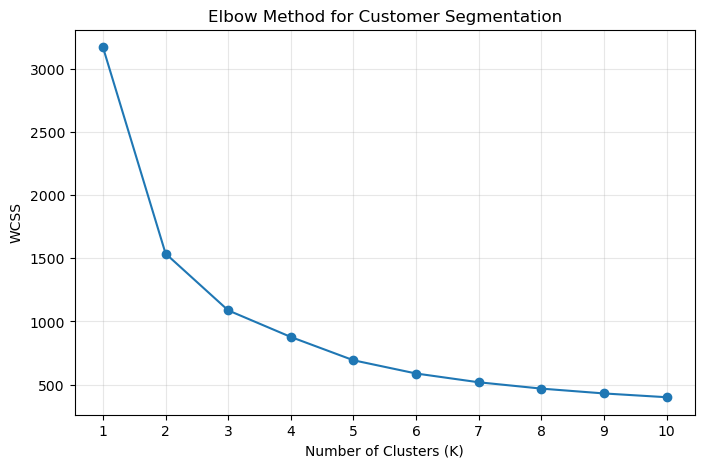

In [21]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Calculate WCSS for different numbers of clusters
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for Customer Segmentation")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)
plt.show()

In [23]:
# Apply K-Means with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Assign a cluster to each customer
customer_data["Cluster"] = kmeans.fit_predict(X_scaled)

# Display customer data with cluster labels
display(customer_data.head(10))

# Count customers in each cluster
print("\nCustomers in each cluster:")
print(customer_data["Cluster"].value_counts().sort_index())

C:\Users\91957\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


,Customer Name,Total_Spending,Unique_Products,Product_Categories,Sub_Categories,Cities,Regions,Sales_Records,Cluster
0,Aaron Bergman,886.156,6,3,5,3,2,6,0
1,Aaron Hawkins,1744.700,11,3,10,6,3,11,2
2,Aaron Smayling,3050.692,10,3,6,7,4,10,2
3,Adam Bellavance,7755.620,17,3,8,8,4,18,1
4,Adam Hart,3250.337,20,3,11,10,4,20,1
5,Adam Shillingsburg,3255.310,24,3,12,7,4,25,1
6,Adrian Barton,14473.571,20,3,9,9,4,20,1
7,Adrian Hane,1735.514,16,3,8,7,3,16,2
8,Adrian Shami,58.820,3,2,3,2,2,3,0
9,Aimee Bixby,966.710,12,3,6,5,2,12,2



Customers in each cluster:
Cluster
0    294
1    153
2    346
Name: count, dtype: int64


In [25]:
# Compare the average characteristics of each cluster
cluster_summary = customer_data.groupby("Cluster").agg(
    Customer_Count=("Customer Name", "count"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Unique_Products=("Unique_Products", "mean"),
    Average_Sub_Categories=("Sub_Categories", "mean"),
    Average_Sales_Records=("Sales_Records", "mean")
).round(2)

display(cluster_summary)

,Customer_Count,Average_Spending,Average_Unique_Products,Average_Sub_Categories,Average_Sales_Records
Cluster,,,,,
0,294,1133.79,6.66,4.97,6.68
1,153,5540.16,21.74,10.73,21.92
2,346,3123.00,12.91,8.20,12.95


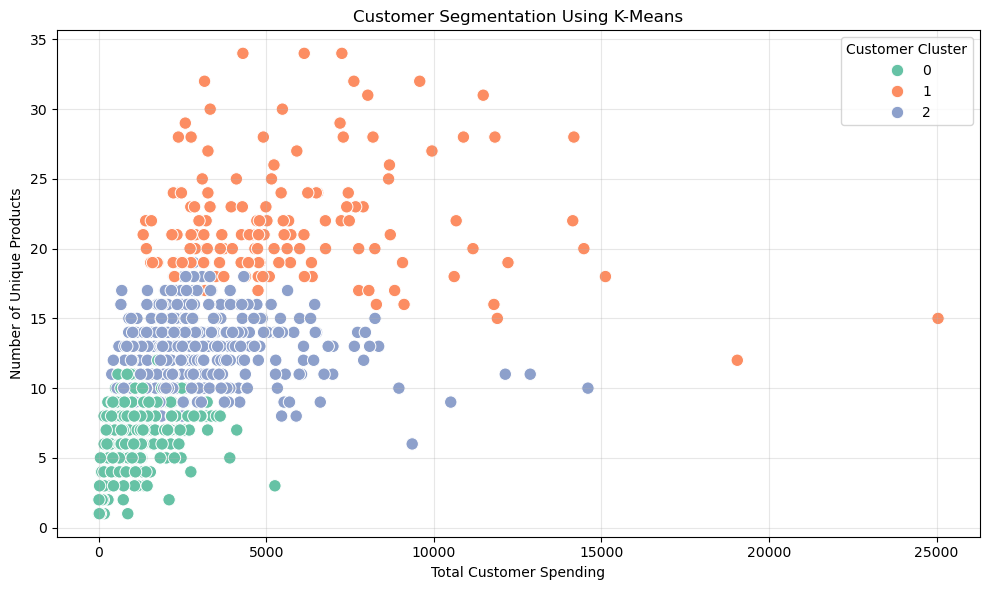

In [27]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_data,
    x="Total_Spending",
    y="Unique_Products",
    hue="Cluster",
    palette="Set2",
    s=80
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Total Customer Spending")
plt.ylabel("Number of Unique Products")
plt.legend(title="Customer Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

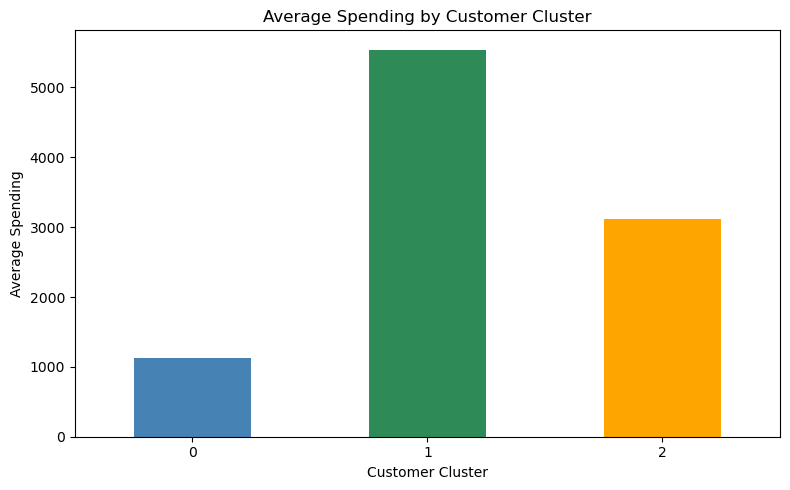

In [29]:
cluster_summary["Average_Spending"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "seagreen", "orange"]
)

plt.title("Average Spending by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Spending")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
# Export customer data with cluster labels
customer_data.to_csv("customer_segments.csv", index=False)

print("Customer segmentation results exported successfully!")

Customer segmentation results exported successfully!


In [33]:
# Create a summary of the customer clusters
cluster_summary = customer_data.groupby("Cluster").agg(
    Customer_Count=("Customer Name", "count"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Unique_Products=("Unique_Products", "mean"),
    Average_Sub_Categories=("Sub_Categories", "mean"),
    Average_Sales_Records=("Sales_Records", "mean")
).round(2)

display(cluster_summary)

# Export the summary
cluster_summary.to_csv("cluster_summary.csv")

print("Cluster summary exported successfully!")

,Customer_Count,Average_Spending,Average_Unique_Products,Average_Sub_Categories,Average_Sales_Records
Cluster,,,,,
0,294,1133.79,6.66,4.97,6.68
1,153,5540.16,21.74,10.73,21.92
2,346,3123.00,12.91,8.20,12.95


Cluster summary exported successfully!
